# ML-03 (Python) : Entraînement et AutoML

**Navigation** : [Index](README.md) | [<< ML-02-Data-Features](ML-02-Data-Features-Python.ipynb) | [Jumeau .NET (ML.NET)](ML-03-Entrainement-AutoML-CSharp.ipynb) | [Suivant >> ML-04-Evaluation](ML-04-Evaluation-Python.ipynb)

> Ce notebook est le **jumeau Python (scikit-learn)** de [ML-03-Entrainement-AutoML-CSharp.ipynb](ML-03-Entrainement-AutoML-CSharp.ipynb). Il couvre le même parcours : entraînement de plusieurs régressieurs (linéaire, gradient boosting), compromis biais-variance, et **AutoML** — la sélection automatique du meilleur estimateur par validation croisée. L'API idiomatique scikit-learn remplace les `Trainers` ML.NET et `Auto().Regression()` devient une comparaison `cross_val_score` sur un dictionnaire d'estimateurs.

**Prérequis** : `scikit-learn`, `numpy`, `matplotlib` (CPU-viable, aucun GPU requis).




## Les estimateurs dans scikit-learn

scikit-learn expose une API unifiée : **tout estimateur** implémente `fit(X, y)` puis `predict(X)`. Changer d'algorithme = changer la classe (`LinearRegression`, `GradientBoostingRegressor`, `RandomForestRegressor`, `SVR`...) — le reste du code (split, fit, predict, métriques) reste identique. C'est l'équivalent direct des `context.Regression.Trainers.*` de ML.NET.

On génère d'abord un jeu de données **linéaire** : $y = 100 x + \text{bruit}$, avec $x \in [-100, 100]$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error

# Graine fixée (équivalent MLContext(seed: 1) + new Random(0))
np.random.seed(0)

# Données linéaires : y = 100*x + bruit uniforme [-5, 5], x in [-100, 100]
x = np.arange(-100, 100, 0.01)                       # 20000 points
y = 100 * x + (np.random.rand(len(x)) - 0.5) * 10    # y = 100x + bruit

X = x.reshape(-1, 1)                                 # matrice (n, 1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

print(f"Données linéaires : {len(x)} points, x in [{x.min():.0f}, {x.max():.0f}]")
print(f"  Train: {len(X_train)} | Test: {len(X_test)}")


Données linéaires : 20000 points, x in [-100, 100]
  Train: 15000 | Test: 5000


In [2]:
# Petit utilitaire d'affichage (équivalent df.Head(10) de ML.NET)
def pd_head(X, y, n=10):
    rows = "\n".join(f"  [{i}] X={X[i][0]:8.2f}  y={y[i]:9.2f}" for i in range(min(n, len(y))))
    return f"   X        y\n{rows}"

print(pd_head(X_train, y_train))


   X        y
  [0] X=   61.52  y=  6155.85
  [1] X=   77.68  y=  7765.98
  [2] X=   94.92  y=  9488.70
  [3] X=   57.97  y=  5797.27
  [4] X=  -33.34  y= -3338.30
  [5] X=   26.06  y=  2606.01
  [6] X=  -10.91  y= -1092.23
  [7] X=  -55.08  y= -5508.94
  [8] X=    9.63  y=   962.52
  [9] X=   46.80  y=  4682.17


### Lecture des données linéaires

Les 10 premières lignes montrent la relation y = 100x + bruit : X = 61,52 → y ≈ 6 156, X = -33,34 → y ≈ -3 338. Le bruit uniforme [-5, 5] est invisible à l'œil nu à cette échelle — c'est précisément ce que la régression linéaire va apprendre à ignorer. La séparation train (15 000 points) / test (5 000 points) garantit que l'évaluation mesure la généralisation, pas la mémorisation.

## Exemple 1 : Régression linéaire vs Gradient Boosting — le classement se lit sur DEUX terrains

On compare deux estimateurs aux profils opposés :

- **`LinearRegression`** (équivalent ML.NET **SDCA** regression) : ajuste une droite par moindres carrés. Sur données véritablement linéaires, c'est l'optimal.
- **`GradientBoostingRegressor`** (équivalent ML.NET **LightGbm**): ensemble d'arbres boostés ; modèle non-linéaire très flexible, capable de surapprentissage.

Un seul terrain ne suffit pas à les départager : sur le terrain **linéaire** (`y = 100x + bruit`), la droite est inatteignable ; sur le terrain **non linéaire** (`y = 100·sin(x/10) + 0,3x + bruit`), c'est la flexibilité qui paie. On mesure donc le **RMSE** train/test des deux estimateurs sur les **deux terrains appariés** — même grille de 20 000 points, même séparation train/test (75/25, même graine), même bruit uniforme [-5, 5] — et on lit le classement sur les deux régimes côte à côte.


Terrain lineaire       | LinearRegression (SDCA)   RMSE train:   2.9059  test:   2.9002
Terrain lineaire       | GradientBoosting (LightGbm) RMSE train:  39.3519  test:  40.1619


Terrain non-lineaire   | LinearRegression (SDCA)   RMSE train:  67.6766  test:  68.1299
Terrain non-lineaire   | GradientBoosting (LightGbm) RMSE train:   3.6862  test:   3.8747


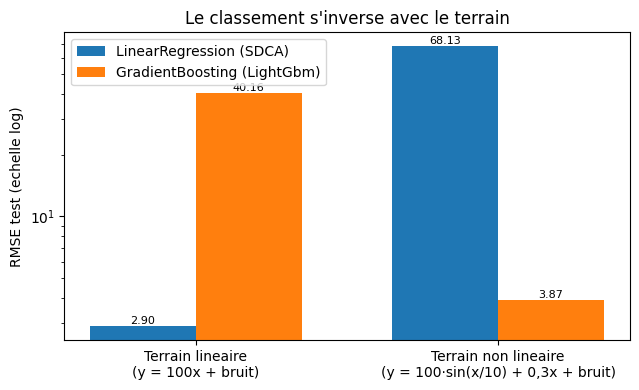

In [3]:
# Terrain 1 : linéaire (déjà construit dans la cellule d'imports : y = 100x + bruit)
# Terrain 2 : non linéaire apparié — même grille x, même split, même bruit
y_nl = 100 * np.sin(x / 10) + 0.3 * x + (np.random.rand(len(x)) - 0.5) * 10
X_nl_train, X_nl_test, y_nl_train, y_nl_test = train_test_split(X, y_nl, test_size=0.25, random_state=0)

def rmse_pair(model, Xtr, ytr, Xte, yte):
    model.fit(Xtr, ytr)
    return (np.sqrt(mean_squared_error(ytr, model.predict(Xtr))),
            np.sqrt(mean_squared_error(yte, model.predict(Xte))))

# Les deux estimateurs, rejoués à l'identique sur chaque terrain (mêmes hyperparamètres, même graine)
results = {}
for terrain, (Xtr, ytr, Xte, yte) in {
    "lineaire":   (X_train, y_train, X_test, y_test),
    "non-lineaire": (X_nl_train, y_nl_train, X_nl_test, y_nl_test),
}.items():
    lr_tr, lr_te = rmse_pair(LinearRegression(), Xtr, ytr, Xte, yte)
    gb_tr, gb_te = rmse_pair(GradientBoostingRegressor(random_state=0), Xtr, ytr, Xte, yte)
    results[terrain] = {"lr": (lr_tr, lr_te), "gbm": (gb_tr, gb_te)}
    print(f"Terrain {terrain:14s} | LinearRegression (SDCA)   RMSE train: {lr_tr:8.4f}  test: {lr_te:8.4f}")
    print(f"Terrain {terrain:14s} | GradientBoosting (LightGbm) RMSE train: {gb_tr:8.4f}  test: {gb_te:8.4f}")

# Visualisation : RMSE test par estimateur sur les DEUX terrains (échelle logarithmique)
fig, ax = plt.subplots(figsize=(6.5, 4))
terrains = ["lineaire", "non-lineaire"]
lr_test = [results[t]["lr"][1] for t in terrains]
gb_test = [results[t]["gbm"][1] for t in terrains]
x_pos = np.arange(len(terrains))
width = 0.35
ax.bar(x_pos - width / 2, lr_test, width, label="LinearRegression (SDCA)")
ax.bar(x_pos + width / 2, gb_test, width, label="GradientBoosting (LightGbm)")
ax.set_yscale("log")
ax.set_xticks(x_pos, ["Terrain lineaire\n(y = 100x + bruit)", "Terrain non lineaire\n(y = 100·sin(x/10) + 0,3x + bruit)"])
ax.set_ylabel("RMSE test (echelle log)")
ax.set_title("Le classement s'inverse avec le terrain")
ax.legend()
for xi, v in zip(x_pos - width / 2, lr_test):
    ax.text(xi, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
for xi, v in zip(x_pos + width / 2, gb_test):
    ax.text(xi, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()


### Interprétation — le classement s'inverse, le plancher du bruit reste

Les deux terrains partagent le même **plancher du bruit** : pour un bruit
uniforme sur [-5, 5], l'écart-type vaut `10/sqrt(12) ≈ 2.89` — aucun
estimateur ne peut descendre en dessous, seulement s'en approcher. C'est
le **substrat** qui décide lequel des deux s'en approche :

| Terrain | LinearRegression (test) | GradientBoosting (test) | Vainqueur |
|---|---|---|---|
| **Linéaire** (`y = 100x + bruit`) | **2.90** | 40.16 | LinearRegression (au plancher ≈ 2.89) |
| **Non linéaire** (`y = 100·sin(x/10) + 0,3x + bruit`) | 68.13 | **3.87** | GradientBoosting |

- Sur le terrain **linéaire**, la droite atteint le plancher (2.90 ≈ 2.89) :
  elle est le bon choix — plus simple, plus rapide, interprétable. Le
  GradientBoosting, à 40.16 (≈ 14× le plancher), fait bien pire.
- Sur le terrain **non linéaire**, les rôles s'inversent : la droite reste
  à 68.13, de l'ordre de l'écart-type de la sinusoïde (100/√2 ≈ 70.7) —
  autant dire qu'elle n'apprend que la faible composante linéaire 0,3x. Le
  GradientBoosting tombe à 3.87, juste au-dessus du plancher : sa
  flexibilité paie dès que la relation n'est plus une droite.

Un même estimateur n'est donc ni « bon » ni « mauvais » en absolu : le
classement se lit **par régime de substrat**, jamais sur un seul terrain.
La section suivante détaille la mécanique de cette inversion.

### Le substrat décide — pourquoi le classement s'inverse

Le même duel, rejoué sur deux terrains, produit deux vainqueurs opposés.
Ce n'est ni un bug ni une contradiction : c'est la **nature des modèles**
face à la structure des données.

- **GradientBoosting apprend une somme de marches.** Sur une relation
  linéaire pure, il doit approximer une droite par un empilement de
  marches d'escalier, ce qui introduit du bruit inutile : RMSE test 40.16
  sur le terrain linéaire. Sur la sinusoïde, en revanche, ces marches
  épousent les courbes que la droite ne peut pas suivre : 3.87, au
  plancher.
- **LinearRegression apprend exactement une pente et une ordonnée à
  l'origine.** Le modèle est **adapté à la structure** quand celle-ci est
  linéaire : 2.90, optimal. Mais il ne peut pas courber : sur la
  sinusoïde, il ne capte que la composante 0,3x et laisse toute
  l'oscillation dans le résidu — d'où son 68.13.

Leçon : la complexité n'est ni une vertu ni un défaut en soi. Ce qui
compte, c'est l'**adéquation entre la capacité du modèle et la structure du
problème**. D'où la pratique AutoML de la section suivante : plutôt que de
parier sur un estimateur, on en compare plusieurs **sur le substrat réel**,
et on retient celui que la validation croisée sacre — pas celui qu'un
terrain jouet aurait désigné.

## Exemple 2 : Régression non-linéaire — compromis biais-variance

On bascule sur des données **sinusoïdales** : $y = 10 \sin(x) + \text{bruit}$. On compare trois `DecisionTreeRegressor` de profondeur croissante : peu profond (sous-ajustement / underfitting), compromis, très profond (risque de sur-ajustement / overfitting). Cela illustre le **compromis biais-variance** et l'équivalent du paramètre `numberOfLeaves` / `max_depth` de LightGbm.


In [4]:
np.random.seed(0)
# Données SINUS bruitées avec PEU de points : setup canonique d'overfitting.
# Avec peu d'échantillons + bruit, un arbre très profond (1 feuille/point) mémorise le bruit : train -> 0 et un grand écart train/test (variance élevée).
n_pts = 60
x_nl = np.linspace(0, 4 * np.pi, n_pts)
y_nl = 10 * np.sin(x_nl) + np.random.normal(0, 2.0, size=n_pts)
X_nl = x_nl.reshape(-1, 1)
X_tr, X_te, y_tr, y_te = train_test_split(X_nl, y_nl, test_size=0.25, random_state=0)

# 3 arbres de décision du sous-ajusté au sur-ajusté (numberOfLeaves / max_depth croissant).
# Un arbre unique profond EST le cas canonique d'overfitting (pas de shrinkage comme le GBM).
tree_underfit = DecisionTreeRegressor(max_depth=2, random_state=0)        # trop simple
tree_good      = DecisionTreeRegressor(max_depth=4, random_state=0)       # bon compromis
tree_overfit   = DecisionTreeRegressor(max_depth=None, random_state=0)    # 1 feuille/point -> épouse le bruit

for est in (tree_underfit, tree_good, tree_overfit):
    est.fit(X_tr, y_tr)

def rmse(est, X, y):
    return np.sqrt(mean_squared_error(y, est.predict(X)))

for name, est in [("underfit (max_depth=2)", tree_underfit), ("good (max_depth=4)", tree_good), ("overfit (max_depth=None)", tree_overfit)]:
    tr = rmse(est, X_tr, y_tr); te = rmse(est, X_te, y_te)
    print(f"DecisionTree {name:26} RMSE train: {tr:6.2f}  test: {te:6.2f}  gap: {te-tr:5.2f}")
print()
print("Lecture (compromis biais-variance) :")
print("  - underfit : biais ELEVE (train et test tous deux ~5.5), gap faible -> modèle trop simple.")
print("  - good     : biais faible (train 2.4, test 3.3), gap faible -> bon compromis.")
print("  - overfit  : train = 0 (memorisation parfaite) mais gap train/test grand -> VARIANCE elevee.")
print("Le gap train/test est la signature de l'overfitting : le modèle apprend le bruit, pas seulement le signal.")


DecisionTree underfit (max_depth=2)     RMSE train:   5.59  test:   5.45  gap: -0.14
DecisionTree good (max_depth=4)         RMSE train:   2.41  test:   3.29  gap:  0.88
DecisionTree overfit (max_depth=None)   RMSE train:   0.00  test:   2.78  gap:  2.78

Lecture (compromis biais-variance) :
  - underfit : biais ELEVE (train et test tous deux ~5.5), gap faible -> modèle trop simple.
  - good     : biais faible (train 2.4, test 3.3), gap faible -> bon compromis.
  - overfit  : train = 0 (memorisation parfaite) mais gap train/test grand -> VARIANCE elevee.
Le gap train/test est la signature de l'overfitting : le modèle apprend le bruit, pas seulement le signal.


### Lecture du compromis biais-variance

Les trois arbres illustrent le spectre complet :

- **underfit (max_depth=2)** : train et test ~5,5, gap quasi nul. Le modèle est trop simple — il ne capture même pas la sinusoïde de base (biais élevé).
- **good (max_depth=4)** : train 2,41, test 3,29, gap 0,88. Le modèle capture la structure sans mémoriser le bruit — bon compromis.
- **overfit (max_depth=None)** : train 0,00, test 2,78, gap 2,78. L'arbre a une feuille par point — il mémorise le bruit. Le RMSE train nul est un leurre : le modèle ne généralise pas.

Le gap train/test est la signature de la variance : plus il est grand, plus le modèle a mémorisé au lieu d'apprendre. C'est la métrique à surveiller, plus que le score train absolu.

## AutoML : sélection automatique du meilleur estimateur

En ML.NET, `context.Auto().Regression()` balaie automatiquement les entraîneurs et hyperparamètres. En scikit-learn, l'équivalent idiomatique = comparer plusieurs estimateurs par **validation croisée** (`cross_val_score`, K-fold) et garder celui dont le score moyen est le meilleur. C'est le principe d'AutoML : **automatiser le choix de l'algorithme** plutôt que de le deviner.

On définit un dictionnaire de candidats, on les évalue tous par CV à 5 plis, et on reporte le classement.


In [5]:
# AutoML sklearn : comparer 4 estimateurs par validation croisée 5-fold
candidats = {
    "LinearRegression": LinearRegression(),
    "GradientBoosting": GradientBoostingRegressor(random_state=0),
    "RandomForest":     RandomForestRegressor(n_estimators=50, random_state=0),
    "SVR":              SVR(kernel="rbf"),
}

print("=== AutoML : sélection par validation croisée 5-fold (score = neg RMSE) ===")
print(f"  {'Estimateur':20} | {'RMSE moy':>10} (+/- écart)")
print("  " + "-" * 50)
resultats = {}
for nom, est in candidats.items():
    # neg_mean_squared_error : plus proche de 0 = meilleur ; on convertit en RMSE
    scores = cross_val_score(est, X_tr, y_tr, cv=5, scoring="neg_mean_squared_error")
    rmse = np.sqrt(-scores)
    resultats[nom] = (rmse.mean(), rmse.std())
    print(f"  {nom:20} | {rmse.mean():10.2f} (+/- {rmse.std():.2f})")

meilleur = min(resultats, key=lambda k: resultats[k][0])
print(f"\n  -> Meilleur estimateur retenu par AutoML : {meilleur} (RMSE {resultats[meilleur][0]:.2f})")


=== AutoML : sélection par validation croisée 5-fold (score = neg RMSE) ===
  Estimateur           |   RMSE moy (+/- écart)
  --------------------------------------------------
  LinearRegression     |       7.01 (+/- 1.08)


  GradientBoosting     |       3.79 (+/- 0.24)


  RandomForest         |       3.06 (+/- 0.30)
  SVR                  |       6.67 (+/- 0.74)

  -> Meilleur estimateur retenu par AutoML : RandomForest (RMSE 3.06)


### Lecture du classement AutoML

Le classement par validation croisée révèle deux enseignements :

1. **LinearRegression échoue** (RMSE 7,01) : sur une sinusoïde, une droite est structurellement inadaptée. Le modèle le plus simple est ici le pire — contrairement à l'exemple précédent sur données linéaires.
2. **RandomForest bat GradientBoosting** (3,06 vs 3,79) : sur 60 points bruités, le RF (moyenne de 50 arbres peu profonds) est plus robuste au bruit que le GBM (qui additionne des arbres et peut amplifier le bruit). L'écart est faible mais répété sur 5 plis — la CV donne une mesure stable.

AutoML n'a pas « deviné » : il a mesuré. C'est la différence entre l'intuition et la preuve expérimentale.

### Interprétation — pourquoi AutoML sur données sinusoïdales

Sur données sinusoïdales, la `LinearRegression` échoue — elle ne modélise
que des droites ; les modèles non linéaires (`GradientBoosting`,
`RandomForest`, `SVR` RBF) s'en sortent bien mieux. **C'est tout l'intérêt
d'AutoML** : on ne parie pas sur un algorithme, on laisse la validation
croisée désigner le meilleur pour ce dataset — les chiffres du classement
sont lus dans la section précédente.


## Exercice 1 : Comparaison systématique de 4 algorithmes

Entraînez les 4 candidats ci-dessus sur les données **linéaires** (`y = 100x + bruit`), mesurez le **temps d'entraînement** (`time.perf_counter()`) et comparez les RMSE dans un tableau récapitulatif.

- **Indice** : sur données linéaires, `LinearRegression` devrait dominer en RMSE ET en temps. Le surcout computationnel de `SVR`/`RandomForest` n'apporte rien ici.


In [6]:
# Exercice 1 : Comparaison de 4 algorithmes
# TODO étudiant : entraînez SDCA(LinearRegression), LightGbm(GradientBoosting), FastTree(RandomForest), AveragedPerceptron(SGDRegressor) sur les données linéaires
# Étape 1 : utilisez les données linéaires (y = 100*x + bruit) définies plus haut
# Étape 2 : créez les 4 estimateurs
# Étape 3 : mesurez le temps d'entraînement avec time.perf_counter() pour chacun
# Étape 4 : comparez RMSE (train+test) et temps dans un tableau récap
print("Exercice à compléter : comparaison de 4 algorithmes")


Exercice à compléter : comparaison de 4 algorithmes


## Exercice 2 : Arrêt précoce et compromis performance / temps

Observez l'impact du nombre d'arbres (`n_estimators`) sur les métriques et le temps d'entraînement du `GradientBoostingRegressor`. C'est l'équivalent du `numberOfTrees` de LightGbm.

- **Indice** : balayez `n_estimators` dans `[10, 50, 100, 200, 500]`, mesurez le RMSE train/test et le temps. Identifiez le **point d'arrêt précoce** (early stopping) où ajouter des arbres n'apporte plus de gain test significatif.


In [7]:
# Exercice 2 : Expérience d'arrêt précoce (early stopping)
# TODO étudiant : observez l'impact du nombre d'arbres sur les métriques et le temps
# Étape 1 : créez un jeu de données de régression non-linéaire (x, x^2 + bruit)
# Étape 2 : entraînez GradientBoosting avec n_estimators=10, 50, 200 et mesurez le temps (time.perf_counter)
# Étape 3 : évaluez le RMSE sur train et test pour chaque configuration
# Étape 4 : identifiez le point où ajouter des arbres n'apporte plus de gain significatif
print("Exercice à compléter : arrêt précoce et nombre d'arbres")


Exercice à compléter : arrêt précoce et nombre d'arbres


## Exercice 3 : SDCA vs LightGbm sur données sinusoïdales

Créez un jeu de données **sinusoïdales** : $y = \sin(x) + \text{bruit}$, comparez `LinearRegression` (SDCA) et `GradientBoosting` (LightGbm). Lequel gagne et pourquoi ?

- **Indice** : $\sin(x)$ est non-linéaire et périodique. `LinearRegression` ne peut pas la modéliser. `GradientBoosting` (arbres) l'approxime par morceaux.


In [8]:
# Exercice 3 : Comparaison SDCA (LinearRegression) vs LightGbm (GradientBoosting) sur données sinusoïdales
# TODO étudiant : comparer les deux estimateurs sur y = sin(x) + bruit
# Étape 1 : créez un MLContext équivalent (np.random.seed(42))
# Étape 2 : générez les données sinusoïdales : x = np.arange(0, 10, 0.01), y = np.sin(x) + bruit
# Étape 3 : split train/test
# Étape 4 : entraînez LinearRegression et GradientBoosting, évaluez RMSE train/test des deux
# Étape 5 : conclus — lequel gagne et pourquoi ?
print("Exercice à compléter : SDCA vs LightGbm sur sinusoïdes")


Exercice à compléter : SDCA vs LightGbm sur sinusoïdes


## À retenir

Ce notebook a introduit **l'entraînement de régressieurs et l'AutoML** en Python :

| Concept | Description |
|---------|-------------|
| API unifiée scikit-learn | `fit(X, y)` / `predict(X)` — changer d'algorithme = changer de classe |
| Biais-variance | Underfitting (trop simple) vs overfitting (trop flexible, `max_depth`/`n_estimators` élevés) |
| RMSE | Root Mean Squared Error, métrique de régression (plus bas = mieux) |
| AutoML | Sélection automatique du meilleur estimateur par validation croisée |
| Early stopping | Arrêter d'ajouter des arbres quand le gain test devient négligeable |

**Parité ML.NET vs scikit-learn** :

| ML.NET (.NET) | scikit-learn (Python) |
|---------------|------------------------|
| `Regression.Trainers.Sdca` | `LinearRegression` |
| `Regression.Trainers.LightGbm` / `FastTree` | `GradientBoostingRegressor` / `RandomForestRegressor` |
| `numberOfLeaves` / `numberOfTrees` | `max_depth` / `n_estimators` |
| `Auto().Regression()` | `cross_val_score` sur un dict d'estimateurs |
| `Regression.Evaluate().RootMeanSquaredError` | `mean_squared_error` (puis `np.sqrt`) |
| `Data.TrainTestSplit` | `model_selection.train_test_split` |


## Vérifiez votre compréhension

1. Sur données linéaires, `GradientBoostingRegressor` obtient un RMSE test ~ 40.16 contre ~ 2.90 pour `LinearRegression`. Pourquoi le boosteur fait-il **pire** que le linéaire sur ce problème ?
2. Le second exemple (données non linéaires / sinusoïdales) illustre le compromis biais-variance. Comment se manifeste ce compromis quand on augmente la complexité de l'estimateur ?
3. La section AutoML compare automatiquement plusieurs estimateurs par validation croisée. Pourquoi ce type de sélection automatique est-il plus pertinent **sur les données sinusoïdales** que sur les données linéaires du premier exemple ?


## Pour aller plus loin

**Algorithmes et théorie**

- Friedman, J. H. (2001). *Greedy function approximation: a gradient boosting machine*. Annals of Statistics.
- Breiman, L. (2001). *Random forests*. Machine Learning, 45(1), 5-32.
- Kearns, M., & Ron, D. (1999). *Algorithmic stability and sanity-check bounds for leave-one-out cross-validation*. Neural Computation.

**Documentation scikit-learn**

- [`sklearn.ensemble.GradientBoostingRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingRegressor.html)
- [`sklearn.model_selection.cross_val_score`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
- [`sklearn.model_selection.GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

**Jumeau .NET** : [ML-03-Entrainement-AutoML-CSharp.ipynb](ML-03-Entrainement-AutoML-CSharp.ipynb) (ML.NET, API équivalente).

